In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('anime.csv')

print("Dataset Shape:", df.shape)
display(df.head())

df.info()

In [26]:
df.shape

(12294, 7)

In [27]:
df.head()

,anime_id,name,genre,type,episodes,rating,members
0,32281,Kimi no Na wa.,"Drama, Romance, School, Supernatural",Movie,1,9.37,200630
1,5114,Fullmetal Alchemist: Brotherhood,"Action, Adventure, Drama, Fantasy, Magic, Mili...",TV,64,9.26,793665
2,28977,Gintama°,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.25,114262
3,9253,Steins;Gate,"Sci-Fi, Thriller",TV,24,9.17,673572
4,9969,Gintama&#039;,"Action, Comedy, Historical, Parody, Samurai, S...",TV,51,9.16,151266


In [28]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12294 entries, 0 to 12293
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   anime_id  12294 non-null  int64  
 1   name      12294 non-null  str    
 2   genre     12232 non-null  str    
 3   type      12269 non-null  str    
 4   episodes  12294 non-null  str    
 5   rating    12064 non-null  float64
 6   members   12294 non-null  int64  
dtypes: float64(1), int64(2), str(4)
memory usage: 672.5 KB


In [29]:
df.describe()

,anime_id,rating,members
count,12294.000000,12064.000000,1.229400e+04
mean,14058.221653,6.473902,1.807134e+04
std,11455.294701,1.026746,5.482068e+04
min,1.000000,1.670000,5.000000e+00
25%,3484.250000,5.880000,2.250000e+02
50%,10260.500000,6.570000,1.550000e+03
75%,24794.500000,7.180000,9.437000e+03
max,34527.000000,10.000000,1.013917e+06


In [30]:
df.isnull().sum()

anime_id      0
name          0
genre        62
type         25
episodes      0
rating      230
members       0
dtype: int64

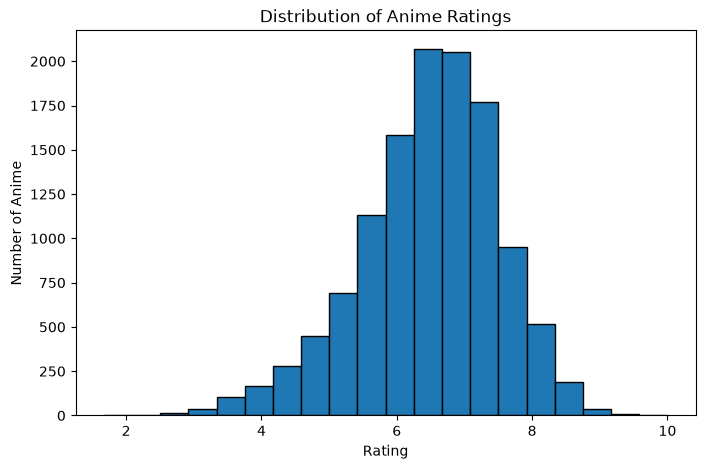

In [10]:
plt.figure(figsize=(8, 5))

plt.hist(df['rating'].dropna(), bins=20, edgecolor='black')

plt.title('Distribution of Anime Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Anime')

plt.show()

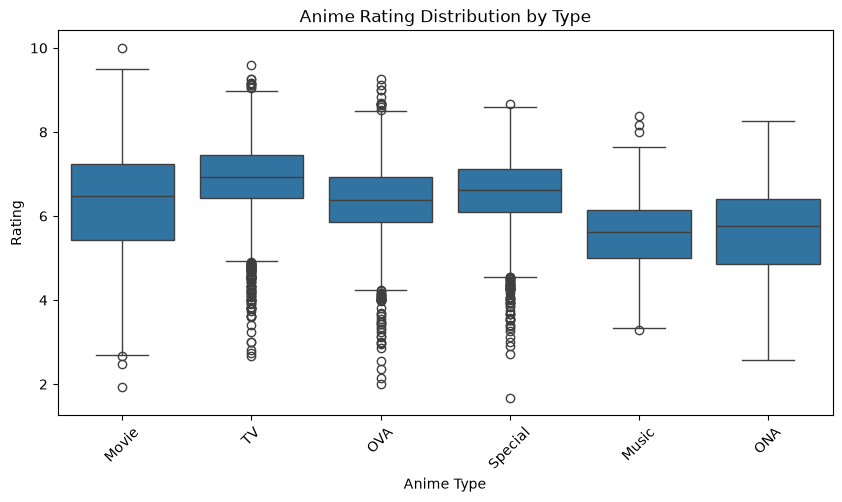

In [11]:
plt.figure(figsize=(10, 5))

sns.boxplot(data=df, x='type', y='rating')

plt.title('Anime Rating Distribution by Type')
plt.xlabel('Anime Type')
plt.ylabel('Rating')
plt.xticks(rotation=45)

plt.show()

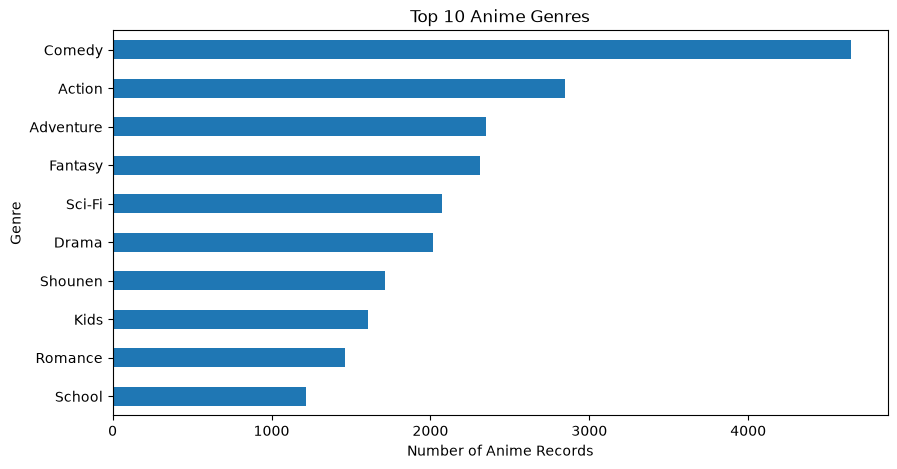

In [12]:
genres = df['genre'].dropna().str.split(', ').explode()

top_genres = genres.value_counts().head(10).sort_values()

plt.figure(figsize=(10, 5))

top_genres.plot(kind='barh')

plt.title('Top 10 Anime Genres')
plt.xlabel('Number of Anime Records')
plt.ylabel('Genre')

plt.show()

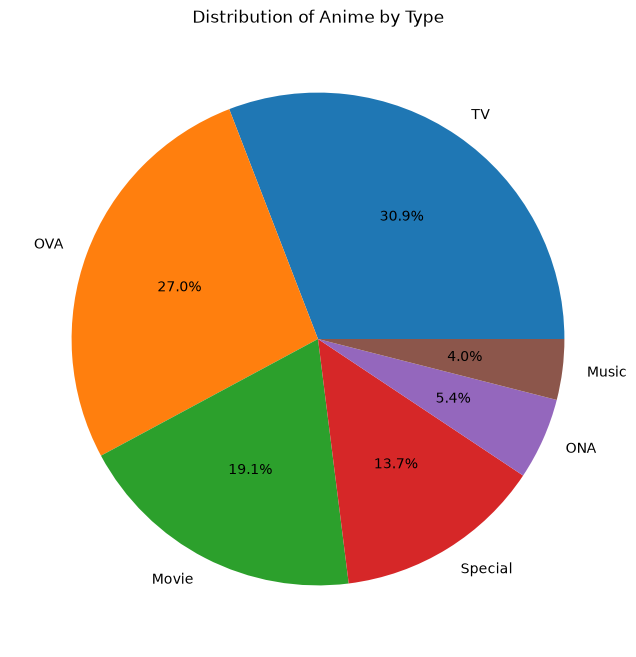

In [13]:
df['type'].value_counts().plot(
    kind='pie',
    autopct='%1.1f%%',
    figsize=(8, 8)
)

plt.title('Distribution of Anime by Type')
plt.ylabel('')

plt.show()

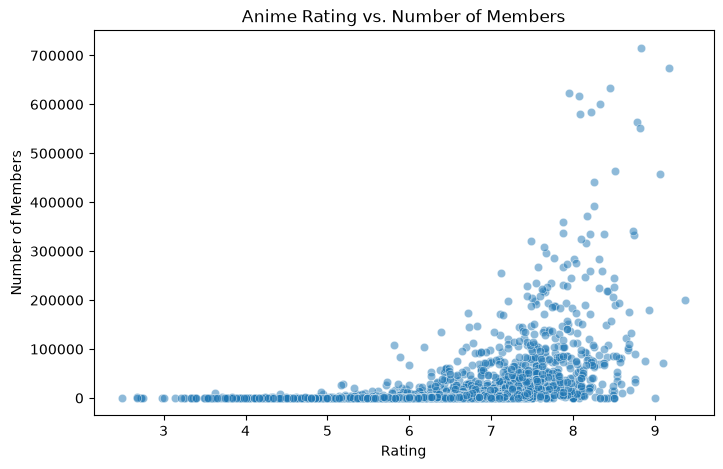

In [14]:
sample_df = df.dropna(subset=['rating', 'members']).sample(
    n=min(3000, len(df.dropna(subset=['rating', 'members']))),
    random_state=42
)

plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=sample_df,
    x='rating',
    y='members',
    alpha=0.5
)

plt.title('Anime Rating vs. Number of Members')
plt.xlabel('Rating')
plt.ylabel('Number of Members')

plt.show()

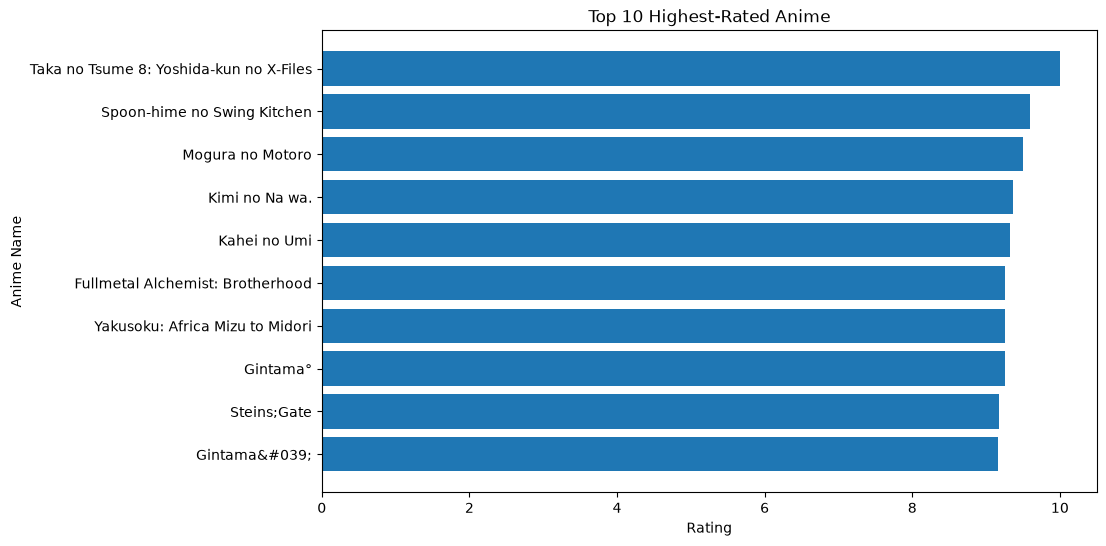

In [15]:
top_anime = (
    df.dropna(subset=['rating'])
    .nlargest(10, 'rating')
    .sort_values('rating')
)

plt.figure(figsize=(10, 6))

plt.barh(top_anime['name'], top_anime['rating'])

plt.title('Top 10 Highest-Rated Anime')
plt.xlabel('Rating')
plt.ylabel('Anime Name')

plt.show()

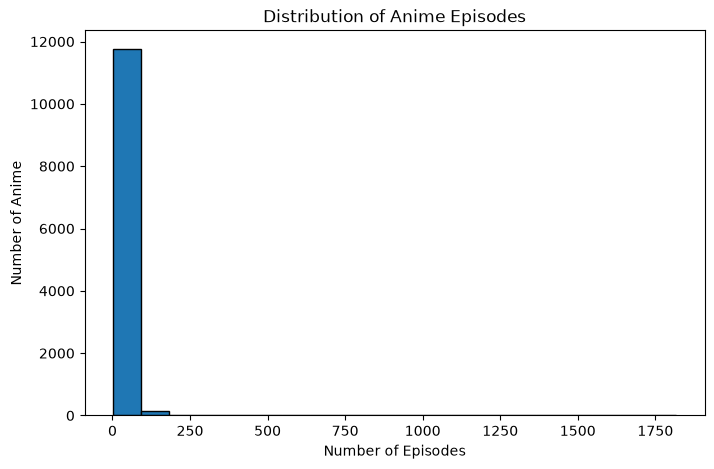

In [16]:
df['episodes_numeric'] = pd.to_numeric(
    df['episodes'],
    errors='coerce'
)

plt.figure(figsize=(8, 5))

plt.hist(
    df['episodes_numeric'].dropna(),
    bins=20,
    edgecolor='black'
)

plt.title('Distribution of Anime Episodes')
plt.xlabel('Number of Episodes')
plt.ylabel('Number of Anime')

plt.show()

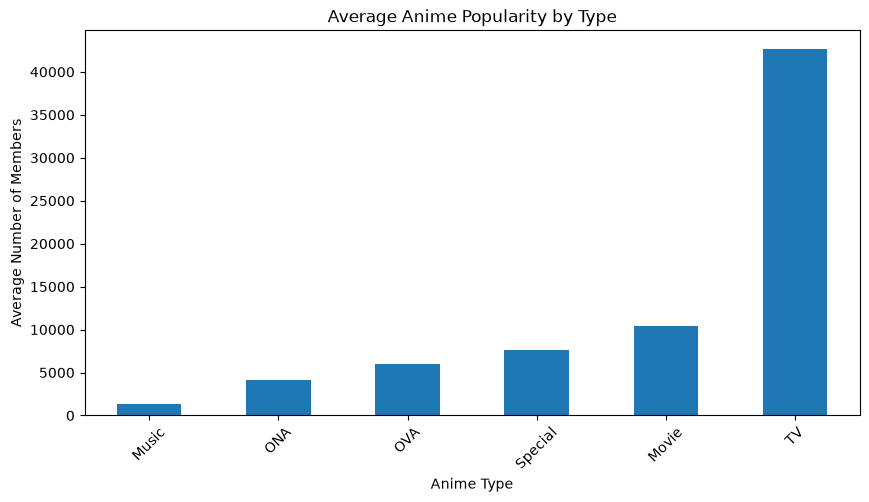

In [17]:
popularity = (
    df.groupby('type')['members']
    .mean()
    .sort_values()
)

plt.figure(figsize=(10, 5))

popularity.plot(kind='bar')

plt.title('Average Anime Popularity by Type')
plt.xlabel('Anime Type')
plt.ylabel('Average Number of Members')
plt.xticks(rotation=45)

plt.show()

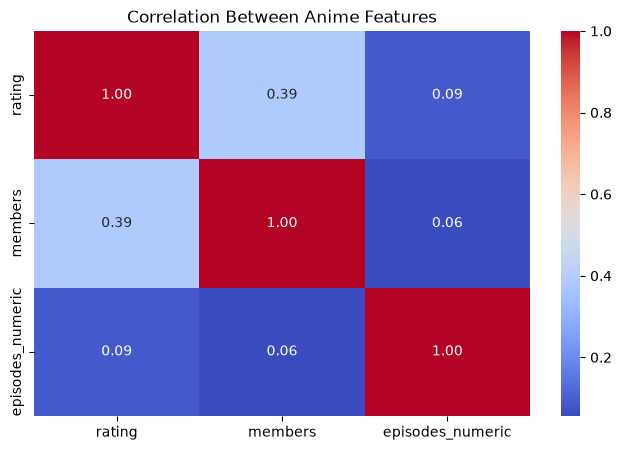

In [18]:
numeric_df = df[
    ['rating', 'members', 'episodes_numeric']
]

plt.figure(figsize=(8, 5))

sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Between Anime Features')

plt.show()

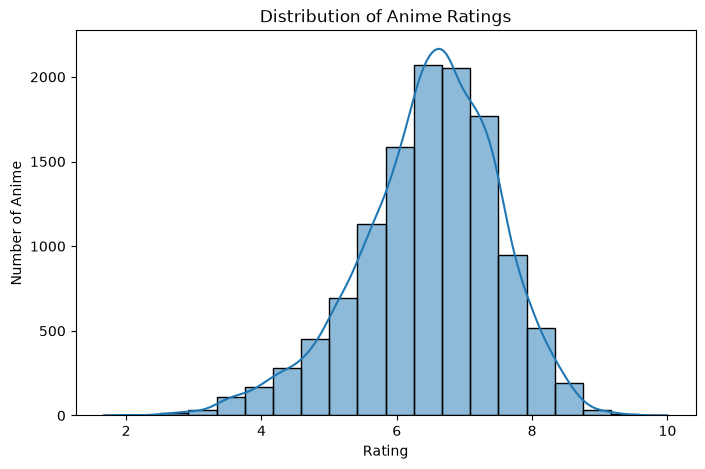

In [19]:
plt.figure(figsize=(8, 5))

sns.histplot(
    df['rating'].dropna(),
    bins=20,
    kde=True,
    edgecolor='black'
)

plt.title('Distribution of Anime Ratings')
plt.xlabel('Rating')
plt.ylabel('Number of Anime')
plt.show()

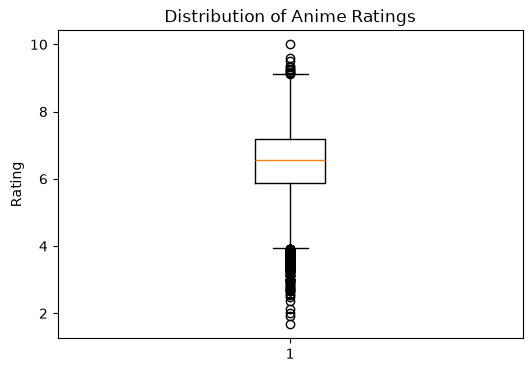

In [20]:
plt.figure(figsize=(6, 4))

plt.boxplot(df['rating'].dropna())

plt.title('Distribution of Anime Ratings')
plt.ylabel('Rating')
plt.show()

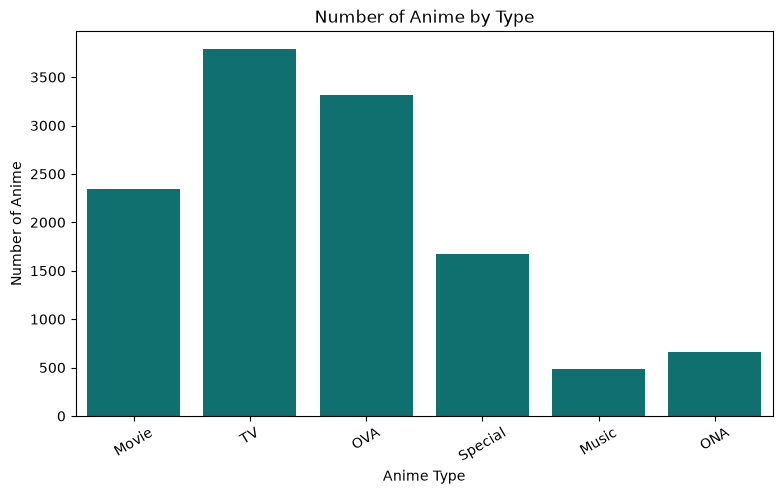

In [21]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='type',
    color='teal'
)

plt.title('Number of Anime by Type')
plt.xlabel('Anime Type')
plt.ylabel('Number of Anime')
plt.xticks(rotation=30)
plt.show()

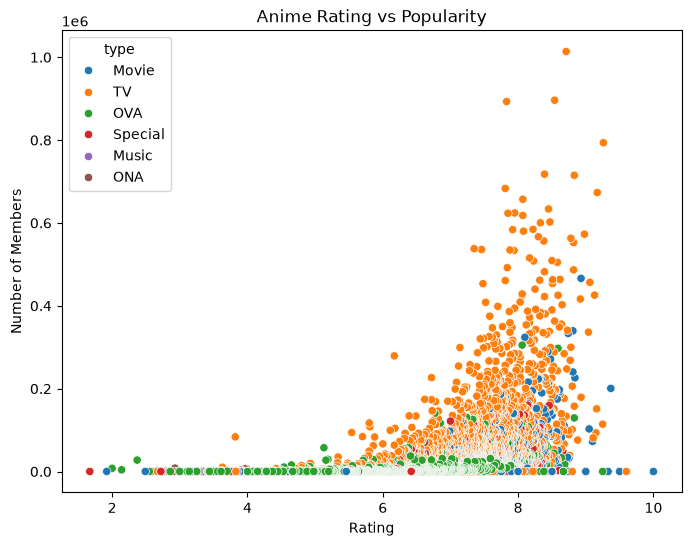

In [22]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x='rating',
    y='members',
    hue='type'
)

plt.title('Anime Rating vs Popularity')
plt.xlabel('Rating')
plt.ylabel('Number of Members')
plt.show()

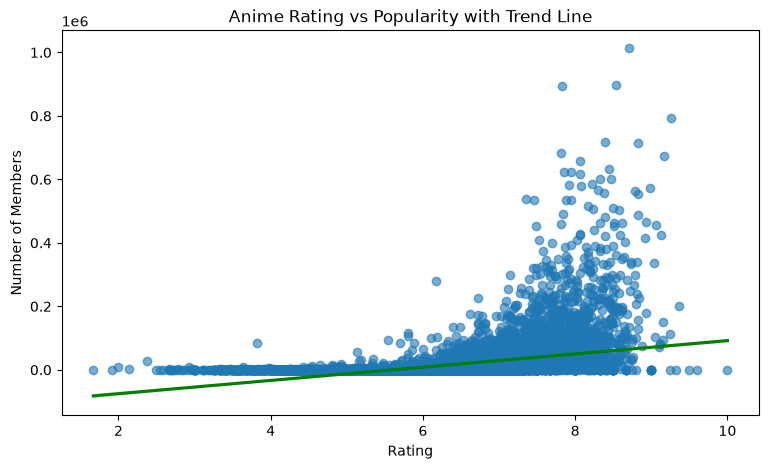

In [23]:
plt.figure(figsize=(9, 5))

sns.regplot(
    data=df,
    x='rating',
    y='members',
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'green'}
)

plt.title('Anime Rating vs Popularity with Trend Line')
plt.xlabel('Rating')
plt.ylabel('Number of Members')
plt.show()

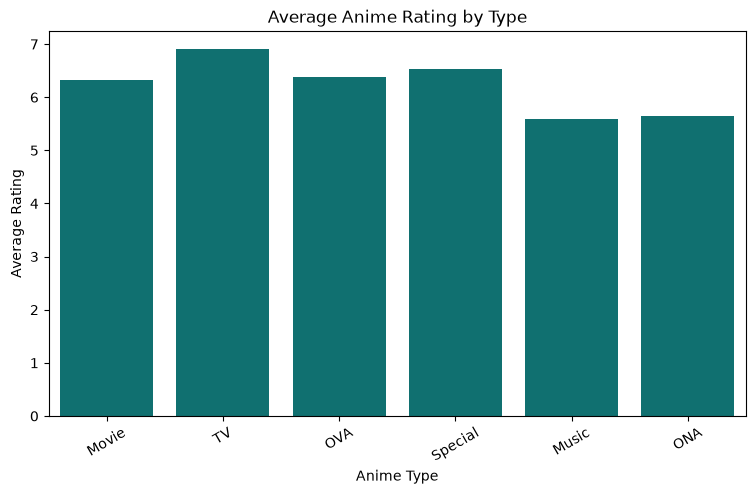

In [24]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df,
    x='type',
    y='rating',
    color='teal',
    errorbar=None
)

plt.title('Average Anime Rating by Type')
plt.xlabel('Anime Type')
plt.ylabel('Average Rating')
plt.xticks(rotation=30)
plt.show()